## Library imports

In [1]:
import os

os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["HF_HOME"] = os.path.join(os.getcwd(), "cache")
os.environ["CUDA_VISIBLE_DEVICES"] = "3"

import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt
import seaborn as sns
import math

from datasets import load_dataset, Dataset, DatasetDict
from evaluate import load
from transformers.utils import logging
from transformers import AutoModelForSequenceClassification, AutoTokenizer, Trainer, TrainingArguments
from sklearn.model_selection import train_test_split
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from IPython.display import display

In [2]:
if torch.cuda.is_available():
    device = torch.device('cuda')
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device('cpu')

print(device)

cuda


## Data loading

In [3]:
verbatim_df = pd.read_csv("../data/verbatim_2026_07_31.csv", sep=";", encoding="utf-8")
dimensions_df = pd.read_csv("../data/Zscores_dimensions.csv", encoding="utf-8")

display(verbatim_df.head())
display(dimensions_df.head())

,ID expérience,Titre,Description
0,280027,ANAH - programme habiter mieux,Nous avons déposé un dossier complet à l'Anah ...
1,280008,Retard de distribution du courrier à la Poste,"Bonjour,depuis plusieurs mois, la Poste distri..."
2,271405,LA PRIME A LA CASSE,J’ai fait une demande de prime à la casse. Ach...
3,279964,Obtention de la copie d'un procès verbal de ré...,Refus du Maire après plusieurs demandes.En fin...
4,279910,Gendarmerie : secret professionnel non respecté,Lors d'un appel au secours (112) faite par une...


,id_experience,satisfaction,perplexite,desillusion,contestation,detresse
0,280177,0.035954,0.090599,1.120834,0.772288,1.055633
1,280171,-0.180208,0.948308,0.379088,0.285955,-0.379695
2,280163,1.358469,-0.552201,-1.197296,-1.038216,-1.397118
3,280174,0.310334,0.047712,-0.086420,-0.445949,1.304659
4,280169,-0.742041,1.124622,1.153119,-0.514206,0.265893


In [4]:
print(len(verbatim_df.index))
verbatim_df = verbatim_df.drop_duplicates("ID expérience")
print(len(verbatim_df.index))

160983
160962


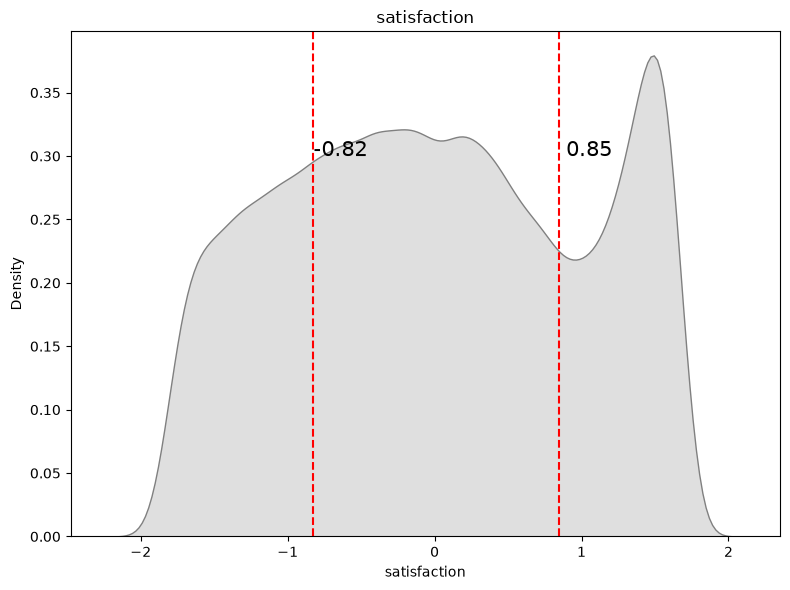

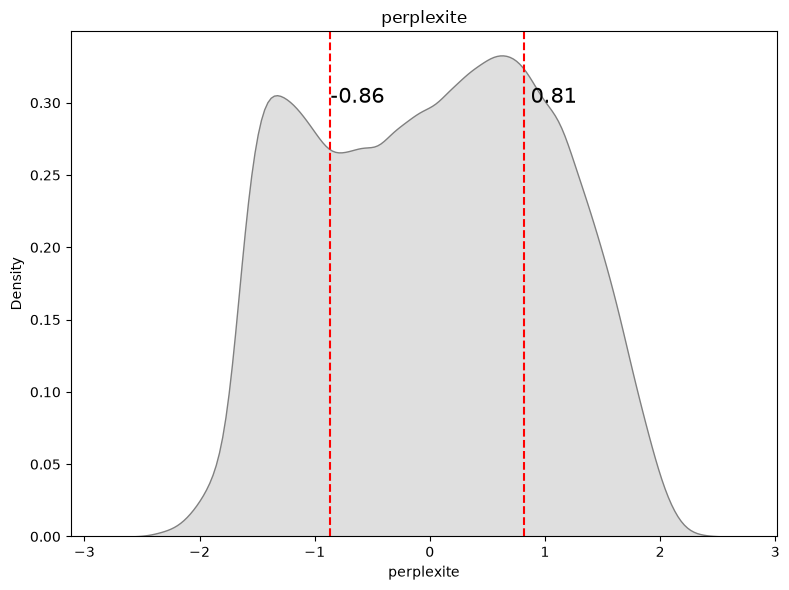

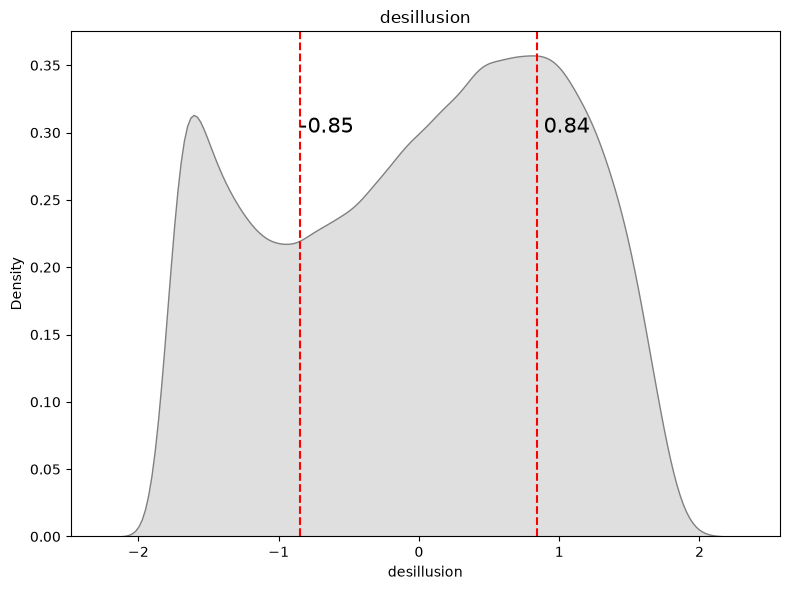

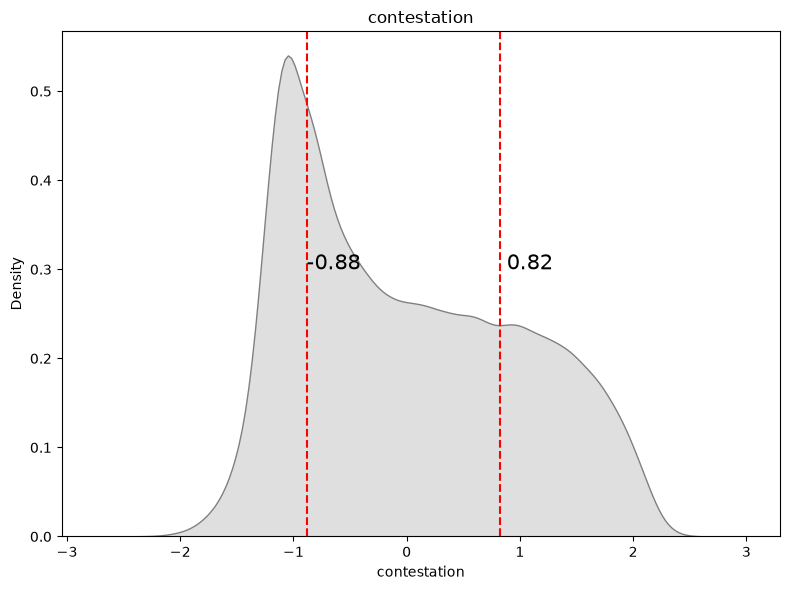

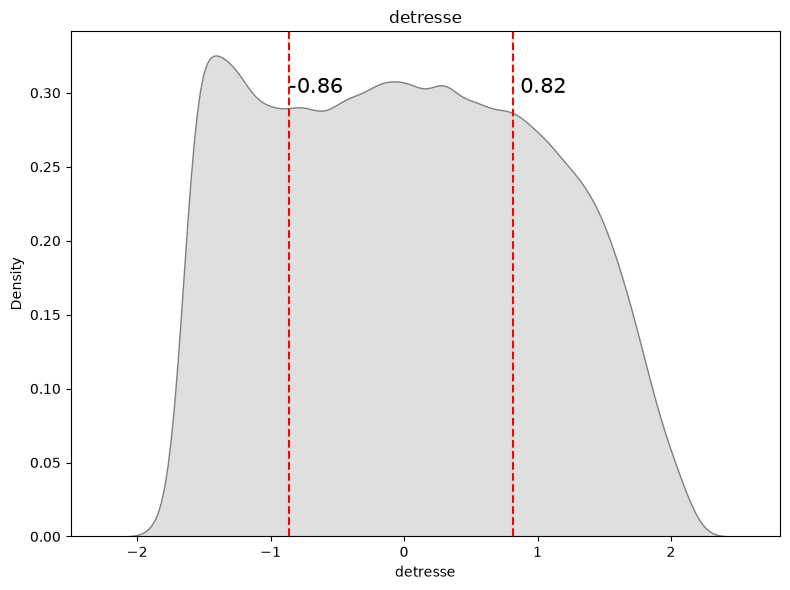

In [5]:
dimensions = ["satisfaction", "perplexite", "desillusion", "contestation", "detresse"]

for dim in dimensions:
    fig, ax = plt.subplots(figsize=(8, 6))
    sns.kdeplot(dimensions_df[dim], color='grey', ax=ax, fill=True)

    q25 = dimensions_df[dim].quantile(0.25)
    q75 = dimensions_df[dim].quantile(0.75)

    ax.axvline(q25, color='red', linestyle="--")
    ax.text(q25, 0.3, f"{q25: .2f}", fontsize=15)
    ax.axvline(q75, color='red', linestyle="--")
    ax.text(q75, 0.3, f"{q75: .2f}", fontsize=15)

    ax.set_title(dim)
    fig.tight_layout()
    plt.show()

In [6]:
dim_thresholds = {
    "satisfaction": 0.839,
    "perplexite": -0.172,
    "desillusion": -0.141,
    "contestation": -0.140,
    "detresse": 0.640
}

for dim, threshold in dim_thresholds.items():
    dimensions_df[f"{dim}_nli"] = (dimensions_df[dim] < threshold).astype(np.int8)

dimensions_df[[f"{dim}_nli" for dim in dimensions]]

,satisfaction_nli,perplexite_nli,desillusion_nli,contestation_nli,detresse_nli
0,1,0,0,0,0
1,1,0,0,0,1
2,0,1,1,1,1
3,1,0,0,1,0
4,1,0,0,1,1
...,...,...,...,...,...
160957,1,1,0,1,0
160958,1,0,1,1,0
160959,0,1,1,1,1
160960,1,0,1,1,1


In [7]:
verbatim_df["full_comment"] = verbatim_df["Titre"] + "\n\n" + verbatim_df["Description"]

In [8]:
verbatim_df.rename(columns={"ID expérience": "id_experience"}, inplace=True)

merged_df = verbatim_df.merge(dimensions_df, on="id_experience", how="inner")
merged_df.head()

,id_experience,Titre,Description,full_comment,satisfaction,perplexite,desillusion,contestation,detresse,satisfaction_nli,perplexite_nli,desillusion_nli,contestation_nli,detresse_nli
0,280027,ANAH - programme habiter mieux,Nous avons déposé un dossier complet à l'Anah ...,ANAH - programme habiter mieux\n\nNous avons d...,-0.912913,1.518875,0.866863,0.573995,0.762334,1,0,0,0,0
1,280008,Retard de distribution du courrier à la Poste,"Bonjour,depuis plusieurs mois, la Poste distri...",Retard de distribution du courrier à la Poste...,-0.911917,0.681989,0.959378,0.668772,-0.799335,1,0,0,0,1
2,271405,LA PRIME A LA CASSE,J’ai fait une demande de prime à la casse. Ach...,LA PRIME A LA CASSE\n\nJ’ai fait une demande d...,1.056911,0.986705,0.550895,0.945588,0.049118,0,0,0,0,1
3,279964,Obtention de la copie d'un procès verbal de ré...,Refus du Maire après plusieurs demandes.En fin...,Obtention de la copie d'un procès verbal de ré...,-0.446126,-0.139423,0.010456,1.296667,-0.880162,1,0,0,0,1
4,279910,Gendarmerie : secret professionnel non respecté,Lors d'un appel au secours (112) faite par une...,Gendarmerie : secret professionnel non respect...,-0.589430,0.939419,-0.398534,1.710874,0.754765,1,0,1,0,0


In [9]:
train_df, val_df = train_test_split(merged_df, test_size=0.2, random_state=1234)
val_df, test_df = train_test_split(val_df, test_size=0.5, random_state=1234)

print(len(train_df.index), len(val_df.index), len(test_df.index))

128769 16096 16097


In [10]:
dst_emotions = DatasetDict({
    "train": Dataset.from_pandas(train_df),
    "valid": Dataset.from_pandas(val_df),
    "test": Dataset.from_pandas(test_df)
})
dst_emotions

DatasetDict({
    train: Dataset({
        features: ['id_experience', 'Titre', 'Description', 'full_comment', 'satisfaction', 'perplexite', 'desillusion', 'contestation', 'detresse', 'satisfaction_nli', 'perplexite_nli', 'desillusion_nli', 'contestation_nli', 'detresse_nli', '__index_level_0__'],
        num_rows: 128769
    })
    valid: Dataset({
        features: ['id_experience', 'Titre', 'Description', 'full_comment', 'satisfaction', 'perplexite', 'desillusion', 'contestation', 'detresse', 'satisfaction_nli', 'perplexite_nli', 'desillusion_nli', 'contestation_nli', 'detresse_nli', '__index_level_0__'],
        num_rows: 16096
    })
    test: Dataset({
        features: ['id_experience', 'Titre', 'Description', 'full_comment', 'satisfaction', 'perplexite', 'desillusion', 'contestation', 'detresse', 'satisfaction_nli', 'perplexite_nli', 'desillusion_nli', 'contestation_nli', 'detresse_nli', '__index_level_0__'],
        num_rows: 16097
    })
})

In [11]:
labels = ["satisfaction", "perplexite", "desillusion", "contestation", "detresse"]
template = "The emotion of this text is {}"

def expand(batch):
    out = {"premise": [], "hypothesis": [], "label": []}
    for i, text in enumerate(batch["full_comment"]):
        for lab in labels:
            out["premise"].append(text)
            out["hypothesis"].append(template.format(lab))
            out["label"].append(int(batch[f"{lab}_nli"][i]))
    return out

dst_nli = dst_emotions.map(
    expand,
    batched=True,
    remove_columns=dst_emotions["train"].column_names,  # required, since the output has more rows than the input
)
dst_nli

Map:   0%|          | 0/128769 [00:00<?, ? examples/s]

Map:   0%|          | 0/16096 [00:00<?, ? examples/s]

Map:   0%|          | 0/16097 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['premise', 'hypothesis', 'label'],
        num_rows: 643845
    })
    valid: Dataset({
        features: ['premise', 'hypothesis', 'label'],
        num_rows: 80480
    })
    test: Dataset({
        features: ['premise', 'hypothesis', 'label'],
        num_rows: 80485
    })
})

In [12]:
dst_nli["train"][0]

{'premise': "Une erreur empêche l'enregistrement des informations saisies.\n\nJe suis à la dernière étape pour soumettre ma demande de renouvellement de titre de séjour, mais je n'arrive pas à soumettre, car j'ai cette erreur qui s'affiche pourtant, j'ai rentré toutes les informations nécessaires.",
 'hypothesis': 'The emotion of this text is satisfaction',
 'label': 1}

## Model training

### Hyperparameters

In [13]:
training_batch_size = 16
num_epochs = 5
lr = 8e-6
weight_decay = 0.01

### Training setup

In [14]:
model_name = "MoritzLaurer/deberta-v3-large-zeroshot-v2.0"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=2, dtype=torch.float32).to(device)

/home/waboucaya/Model_emotions/.venv/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Loading weights:   0%|          | 0/394 [00:00<?, ?it/s]

In [15]:
encoded_dataset = dst_nli.map(lambda example: tokenizer(example["premise"], example["hypothesis"], max_length=512, truncation=True), batched=True)

Map:   0%|          | 0/643845 [00:00<?, ? examples/s]

Map:   0%|          | 0/80480 [00:00<?, ? examples/s]

Map:   0%|          | 0/80485 [00:00<?, ? examples/s]

In [16]:
metric_name = "f1"
metric = load(metric_name)


def compute_metrics(eval_pred):
    predictions, labels = eval_pred
    predictions = np.argmax(predictions, axis=1)
    return {
        "f1_micro": metric.compute(predictions=predictions, references=labels, average="micro")["f1"],
        "f1_macro": metric.compute(predictions=predictions, references=labels, average="macro")["f1"]
    }

In [17]:
print(model.dtype, torch.cuda.device_count())

torch.float32 1


### Training

In [18]:
total_steps = math.ceil(len(encoded_dataset["train"]) / training_batch_size) * num_epochs
warmup_steps = int(0.1 * total_steps)

args = TrainingArguments(
    f"./models/model_emotions",
    warmup_steps=warmup_steps,
    eval_strategy="steps",
    save_strategy="steps",
    eval_steps=5000,
    save_steps=5000,
    logging_steps=100,
    learning_rate=lr,
    per_device_train_batch_size=training_batch_size,
    per_device_eval_batch_size=training_batch_size,
    num_train_epochs=num_epochs,
    weight_decay=weight_decay,
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    save_total_limit=3,
    seed=1234
)

trainer = Trainer(
    model,
    args,
    train_dataset=encoded_dataset["train"],
    eval_dataset=encoded_dataset["valid"],
    processing_class=tokenizer,
    compute_metrics=compute_metrics
)

In [ ]:
logging.set_verbosity_info()

trainer.train()

[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 2, 'bos_token_id': 1}.
[transformers] The following columns in the Training set don't have a corresponding argument in `DebertaV2ForSequenceClassification.forward` and have been ignored: hypothesis, premise. If hypothesis, premise are not expected by `DebertaV2ForSequenceClassification.forward`,  you can safely ignore this message.
[transformers] ***** Running training *****
[transformers]   Num examples = 643,845
[transformers]   Num Epochs = 5
[transformers]   Num update steps per epoch = 40,241
[transformers]   Instantaneous batch size per device = 16
[transformers]   Total train batch size (w. parallel, distributed & accumulation) = 16
[transformers]   Gradient Accumulation steps = 1
[transformers]   Total optimization steps = 201,2

Step,Training Loss,Validation Loss


In [20]:
history = pd.DataFrame(trainer.state.log_history)

evals = history.dropna(subset=["eval_loss"])[
    ["step", "epoch", "eval_loss", "eval_f1_micro", "eval_f1_macro"]
]
display(evals)

,step,epoch,eval_loss,eval_f1_micro,eval_f1_macro
50,5000,0.124251,0.220564,0.913457,0.912102
101,10000,0.248503,0.201910,0.912972,0.912130
152,15000,0.372754,0.224321,0.908039,0.906273
203,20000,0.497006,0.227523,0.904833,0.903151
254,25000,0.621257,0.274557,0.892060,0.888629
305,30000,0.745508,0.226682,0.906585,0.905533
356,35000,0.869760,0.213683,0.905753,0.903427
407,40000,0.994011,0.244806,0.905007,0.904208
458,45000,1.118262,0.255663,0.912997,0.911929
509,50000,1.242514,0.288448,0.911742,0.910246


In [19]:


logging.set_verbosity_info()

trainer.train(
    resume_from_checkpoint=True
)

[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 2, 'bos_token_id': 1}.
[transformers] Loading model from ./models/model_emotions/checkpoint-201205.
[transformers] The following columns in the Training set don't have a corresponding argument in `DebertaV2ForSequenceClassification.forward` and have been ignored: hypothesis, premise. If hypothesis, premise are not expected by `DebertaV2ForSequenceClassification.forward`,  you can safely ignore this message.
[transformers] ***** Running training *****
[transformers]   Num examples = 643,845
[transformers]   Num Epochs = 5
[transformers]   Num update steps per epoch = 40,241
[transformers]   Instantaneous batch size per device = 16
[transformers]   Total train batch size (w. parallel, distributed & accumulation) = 16
[transformers]   Grad

Step,Training Loss,Validation Loss


TrainOutput(global_step=201205, training_loss=0.0, metrics={'train_runtime': 0.0022, 'train_samples_per_second': 1445963621.161, 'train_steps_per_second': 90374270.328, 'total_flos': 2.5475443599342505e+18, 'train_loss': 0.0, 'epoch': 5.0})

### Assessing the model

In [20]:
predictions = trainer.predict(encoded_dataset["test"])
y_pred = predictions.predictions.argmax(-1)
y_true = predictions.label_ids

label_list = ["entailed", "not entailed"]

print(classification_report(y_true, y_pred, target_names=label_list))

[transformers] The following columns in the test set don't have a corresponding argument in `DebertaV2ForSequenceClassification.forward` and have been ignored: hypothesis, premise. If hypothesis, premise are not expected by `DebertaV2ForSequenceClassification.forward`,  you can safely ignore this message.
[transformers] 
***** Running Prediction *****
[transformers]   Num examples = 80485
[transformers]   Batch size = 16


              precision    recall  f1-score   support

    entailed       0.91      0.92      0.92     35151
not entailed       0.94      0.93      0.94     45334

    accuracy                           0.93     80485
   macro avg       0.93      0.93      0.93     80485
weighted avg       0.93      0.93      0.93     80485



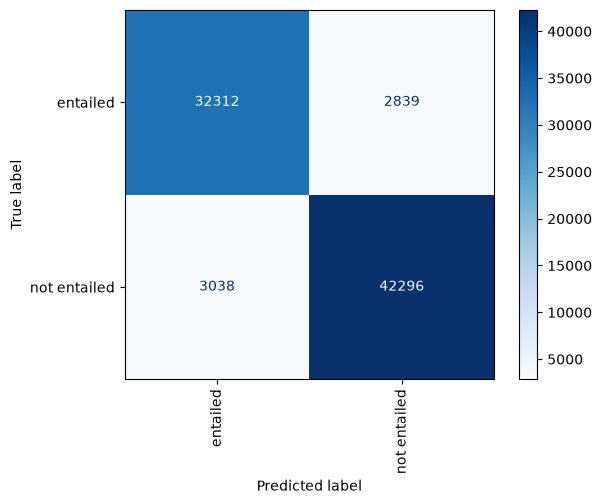

In [21]:
disp = ConfusionMatrixDisplay.from_predictions(
    y_true, 
    y_pred, 
    display_labels=label_list,
    cmap="Blues",
    xticks_rotation="vertical"
)

plt.show()

ValueError: x and y must have same first dimension, but have shapes (2013,) and (41,)

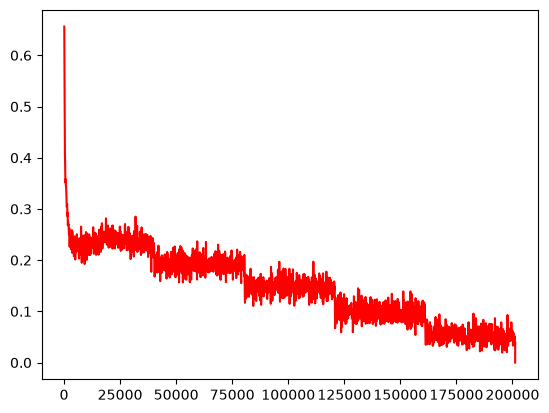

In [22]:
log_history = trainer.state.log_history
x = sorted(list({log["step"] for log in log_history}))
y1 = [log["loss"] if "loss" in log else log["train_loss"] for log in list(filter(lambda log: ("loss" in log) or ("train_loss" in log), log_history))]
y2 = [log["eval_loss"] for log in list(filter(lambda log: "eval_loss" in log, log_history))]

if len(x) < len(y1) or len(x) < len(y2):
    print(f"log_history: {log_history}")
    y1 = y1[:len(x)]
    y2 = y2[:len(x)]

fig, ax = plt.subplots()
ax.plot(x, y1, 'r', label="train_loss")
ax.plot(x, y2, 'g', label="eval_loss")
ax.set_ylim(0, 1)
ax.set_xlabel("Step", fontsize='large')
ax.set_ylabel("Loss", fontsize='large')
ax.legend()
plt.tight_layout()

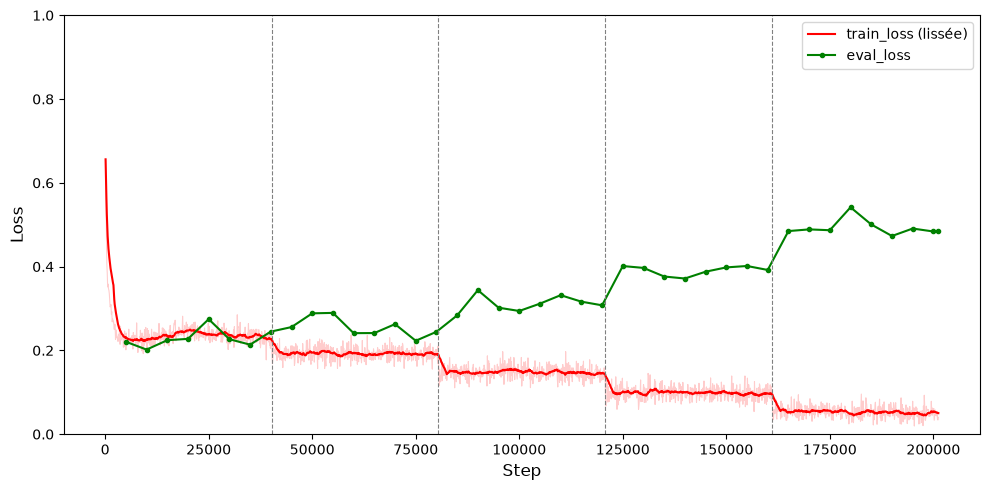

In [23]:
log_history = trainer.state.log_history

train_logs = [log for log in log_history if "loss" in log]       # exclut le résumé "train_loss"
eval_logs  = [log for log in log_history if "eval_loss" in log]

train_steps = [log["step"] for log in train_logs]
train_loss  = [log["loss"] for log in train_logs]
eval_steps  = [log["step"] for log in eval_logs]
eval_loss   = [log["eval_loss"] for log in eval_logs]

# Lissage de la training loss (très bruitée sur 100 steps)
train_smooth = pd.Series(train_loss).rolling(window=20, min_periods=1).mean()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(train_steps, train_loss, color="red", alpha=0.2, linewidth=0.8)
ax.plot(train_steps, train_smooth, color="red", label="train_loss (lissée)")
ax.plot(eval_steps, eval_loss, color="green", marker="o", markersize=3, label="eval_loss")

# Limites d'epochs
steps_per_epoch = trainer.state.max_steps / args.num_train_epochs
for e in range(1, int(args.num_train_epochs)):
    ax.axvline(e * steps_per_epoch, color="gray", linestyle="--", linewidth=0.8)

ax.set_ylim(0, 1)
ax.set_xlabel("Step", fontsize="large")
ax.set_ylabel("Loss", fontsize="large")
ax.legend()
plt.tight_layout()
plt.show()

# Analyse des faux positifs et faux négatifs

In [24]:
print("stop")

stop


In [25]:
PRESENTE = 0  # 0 = présente, 1 = absente
DEBUT, N = 0, 10  # changez DEBUT (0, 10, 20…) pour voir les lignes suivantes

pd.set_option("display.max_colwidth", None)

df = encoded_dataset["test"].select_columns(["premise", "hypothesis", "label"]).to_pandas()
df["y_true"] = y_true
df["y_pred"] = y_pred

faux_positifs = df[(df["y_true"] != PRESENTE) & (df["y_pred"] == PRESENTE)]
faux_negatifs = df[(df["y_true"] == PRESENTE) & (df["y_pred"] != PRESENTE)]

print(len(faux_positifs), "faux positifs |", len(faux_negatifs), "faux négatifs\n")

def lire(erreurs, titre):
    print(f"===== {titre} =====\n")
    for i, row in erreurs.iloc[DEBUT:DEBUT + N].iterrows():
        print(f"[{i}] Hypothèse : {row['hypothesis']}")
        print(f"Texte : {row['premise']}")
        print("-" * 80)
    print()

lire(faux_positifs, "FAUX POSITIFS (émotion prédite à tort)")
lire(faux_negatifs, "FAUX NÉGATIFS (émotion manquée)")

3038 faux positifs | 2839 faux négatifs

===== FAUX POSITIFS (émotion prédite à tort) =====

[4] Hypothèse : The emotion of this text is detresse
Texte : Calcul de retraite

Je souhaitais connaître l'estimation du montant de ma retraite via "Mon compte retraite" mais je n'ai abouti qu'à une page d'erreur.
--------------------------------------------------------------------------------
[29] Hypothèse : The emotion of this text is detresse
Texte : rendez-vous au consulat à Londres

Impérativement le rendez-vous se prend en ligne, c'est très compliqué, les "priorités" du Consulat se réduisent et tant pis pour les Français qui n'obtiennent pas de rendez-vous.
Quant au téléphone, personne ne répond, ils sont "debordés"
--------------------------------------------------------------------------------
[34] Hypothèse : The emotion of this text is detresse
Texte : Impossibilité de connexion à impôts.gouv

Il se passe des choses bizarres sur le site des impôts depuis l'évolution vers les Finances

[transformers] The following columns in the test set don't have a corresponding argument in `DebertaV2ForSequenceClassification.forward` and have been ignored: hypothesis, premise. If hypothesis, premise are not expected by `DebertaV2ForSequenceClassification.forward`,  you can safely ignore this message.
[transformers] 
***** Running Prediction *****
[transformers]   Num examples = 80480
[transformers]   Batch size = 16


Lignes sans score : 0
Labels cohérents avec score > 0 : 0.8863 



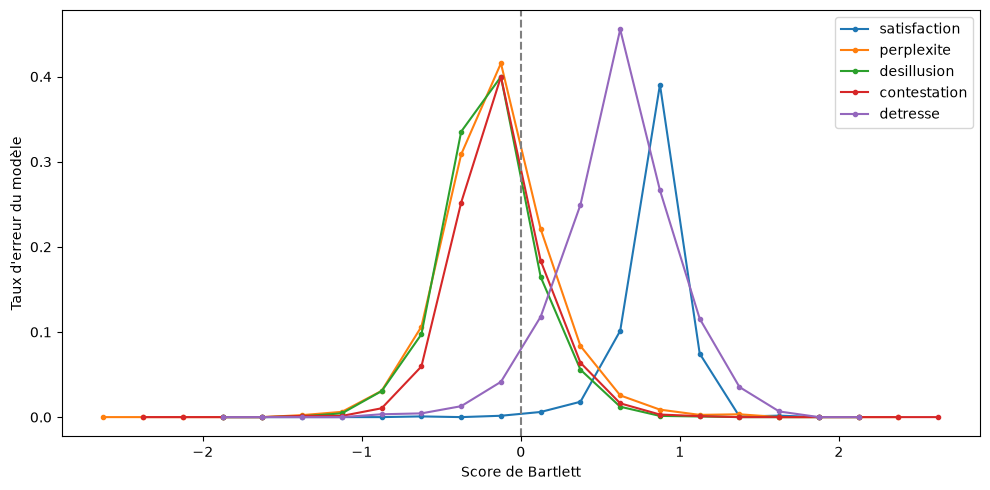

,zone exclue,% données gardées,taux FP,taux FN,accuracy
0,|score| < 0,100.0,0.0668,0.0810,0.9270
1,|score| < 0.1,94.1,0.0684,0.0627,0.9341
2,|score| < 0.25,85.0,0.0566,0.0473,0.9474
3,|score| < 0.5,70.3,0.0290,0.0444,0.9640
4,|score| < 0.75,55.7,0.0088,0.0373,0.9775
5,|score| < 1.0,40.9,0.0011,0.0149,0.9921


In [26]:

import unicodedata

PRESENTE = 0
EMOTIONS = ["satisfaction", "perplexite", "desillusion", "contestation", "detresse"]

def sans_accents(s):
    return unicodedata.normalize("NFKD", s).encode("ascii", "ignore").decode().lower()

def trouver_emotion(h):
    h = sans_accents(h)
    return next((e for e in EMOTIONS if e in h), "inconnue")

# --- Prédictions sur la validation ---
ds = encoded_dataset["valid"]
out = trainer.predict(ds)
probs = torch.softmax(torch.tensor(out.predictions), dim=-1).numpy()

df = ds.select_columns(["premise", "hypothesis", "label"]).to_pandas()
df["y_pred"] = probs.argmax(axis=1)
df["p_presente"] = probs[:, PRESENTE]
df["emotion"] = df["hypothesis"].apply(trouver_emotion)

# --- Score de Bartlett de chaque paire ---
scores = (merged_df.drop_duplicates(subset="full_comment")
          .melt(id_vars="full_comment", value_vars=EMOTIONS,
                var_name="emotion", value_name="score"))
df = df.merge(scores, left_on=["premise", "emotion"],
              right_on=["full_comment", "emotion"], how="left").drop(columns="full_comment")

print("Lignes sans score :", df["score"].isna().sum())
print("Labels cohérents avec score > 0 :",
      round(((df["score"] > 0) == (df["label"] == PRESENTE)).mean(), 4), "\n")

df["fp"] = (df["label"] != PRESENTE) & (df["y_pred"] == PRESENTE)
df["fn"] = (df["label"] == PRESENTE) & (df["y_pred"] != PRESENTE)
df["erreur"] = df["fp"] | df["fn"]

# --- 1. Taux d'erreur selon le score de Bartlett ---
df["tranche"] = pd.cut(df["score"], bins=np.arange(-3, 3.01, 0.25))
taux = df.groupby(["emotion", "tranche"], observed=True)["erreur"].mean().reset_index()
taux["centre"] = taux["tranche"].apply(lambda x: x.mid)

fig, ax = plt.subplots(figsize=(10, 5))
for e in EMOTIONS:
    t = taux[taux["emotion"] == e]
    ax.plot(t["centre"], t["erreur"], marker="o", markersize=3, label=e)
ax.axvline(0, color="gray", linestyle="--")
ax.set_xlabel("Score de Bartlett")
ax.set_ylabel("Taux d'erreur du modèle")
ax.legend()
plt.tight_layout()
plt.show()

# --- 2. Performances en écartant une zone autour de 0 ---
lignes = []
for delta in [0, 0.1, 0.25, 0.5, 0.75, 1.0]:
    sub = df[df["score"].abs() >= delta]
    lignes.append({
        "zone exclue": f"|score| < {delta}",
        "% données gardées": round(100 * len(sub) / len(df), 1),
        "taux FP": round(sub["fp"].sum() / (sub["label"] != PRESENTE).sum(), 4),
        "taux FN": round(sub["fn"].sum() / (sub["label"] == PRESENTE).sum(), 4),
        "accuracy": round(1 - sub["erreur"].mean(), 4),
    })
display(pd.DataFrame(lignes))

In [27]:
lignes = []
pred_presente = df["y_pred"] == PRESENTE

for seuil in np.round(np.arange(0, 0.51, 0.05), 2):
    vrai_presente = df["score"] > seuil   # nouveau label : présente si score > seuil
    fp = (pred_presente & ~vrai_presente).sum()
    fn = (~pred_presente & vrai_presente).sum()
    lignes.append({
        "seuil": seuil,
        "% labels présents": round(100 * vrai_presente.mean(), 1),
        "taux FP": round(fp / (~vrai_presente).sum(), 4),
        "taux FN": round(fn / vrai_presente.sum(), 4),
        "accuracy": round((pred_presente == vrai_presente).mean(), 4),
    })

display(pd.DataFrame(lignes))

,seuil,% labels présents,taux FP,taux FN,accuracy
0,0.00,49.8,0.0850,0.2020,0.8567
1,0.05,48.4,0.0949,0.1914,0.8584
2,0.10,46.9,0.1049,0.1796,0.8601
3,0.15,45.3,0.1165,0.1693,0.8596
4,0.20,43.8,0.1279,0.1591,0.8585
5,0.25,42.2,0.1389,0.1476,0.8574
6,0.30,40.8,0.1499,0.1378,0.8551
7,0.35,39.3,0.1603,0.1267,0.8529
8,0.40,37.8,0.1716,0.1170,0.8490
9,0.45,36.2,0.1834,0.1064,0.8444


In [28]:
for s in [0.3, 0.4, 0.5, 0.6, 0.7]:
    pred = df["p_presente"] >= s
    vrai = df["label"] == PRESENTE
    print(f"seuil {s} : taux FP = {(pred & ~vrai).sum() / (~vrai).sum():.4f} | "
          f"taux FN = {(~pred & vrai).sum() / vrai.sum():.4f}")

seuil 0.3 : taux FP = 0.0672 | taux FN = 0.0806
seuil 0.4 : taux FP = 0.0670 | taux FN = 0.0808
seuil 0.5 : taux FP = 0.0668 | taux FN = 0.0810
seuil 0.6 : taux FP = 0.0666 | taux FN = 0.0812
seuil 0.7 : taux FP = 0.0666 | taux FN = 0.0814


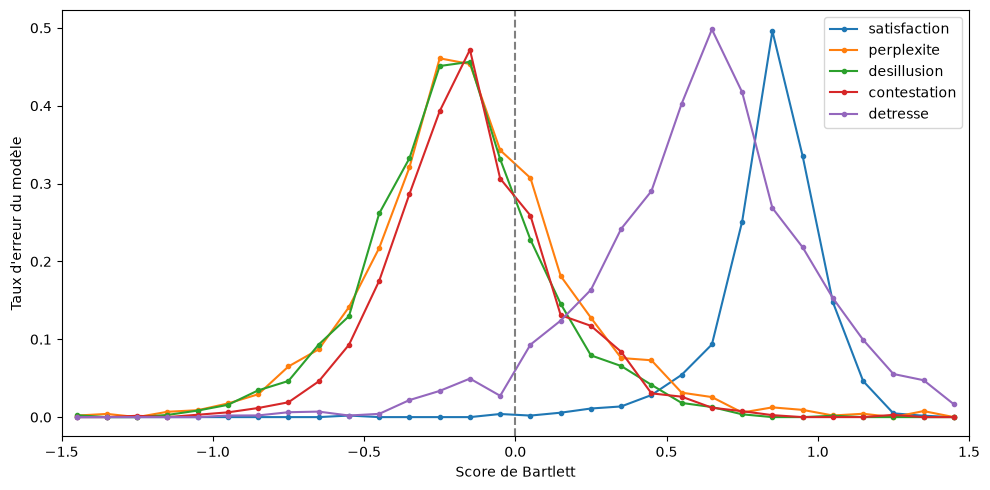

In [29]:
bins = np.arange(-1.5, 1.51, 0.1)  # tranches plus fines pour le zoom

df["tranche_zoom"] = pd.cut(df["score"], bins=bins)
taux = df.groupby(["emotion", "tranche_zoom"], observed=True)["erreur"].mean().reset_index()
taux["centre"] = taux["tranche_zoom"].apply(lambda x: x.mid).astype(float)

fig, ax = plt.subplots(figsize=(10, 5))
for e in EMOTIONS:
    t = taux[taux["emotion"] == e]
    ax.plot(t["centre"], t["erreur"], marker="o", markersize=3, label=e)

ax.axvline(0, color="gray", linestyle="--")
ax.set_xlim(-1.5, 1.5)
ax.set_xlabel("Score de Bartlett")
ax.set_ylabel("Taux d'erreur du modèle")
ax.legend()
plt.tight_layout()
plt.show()

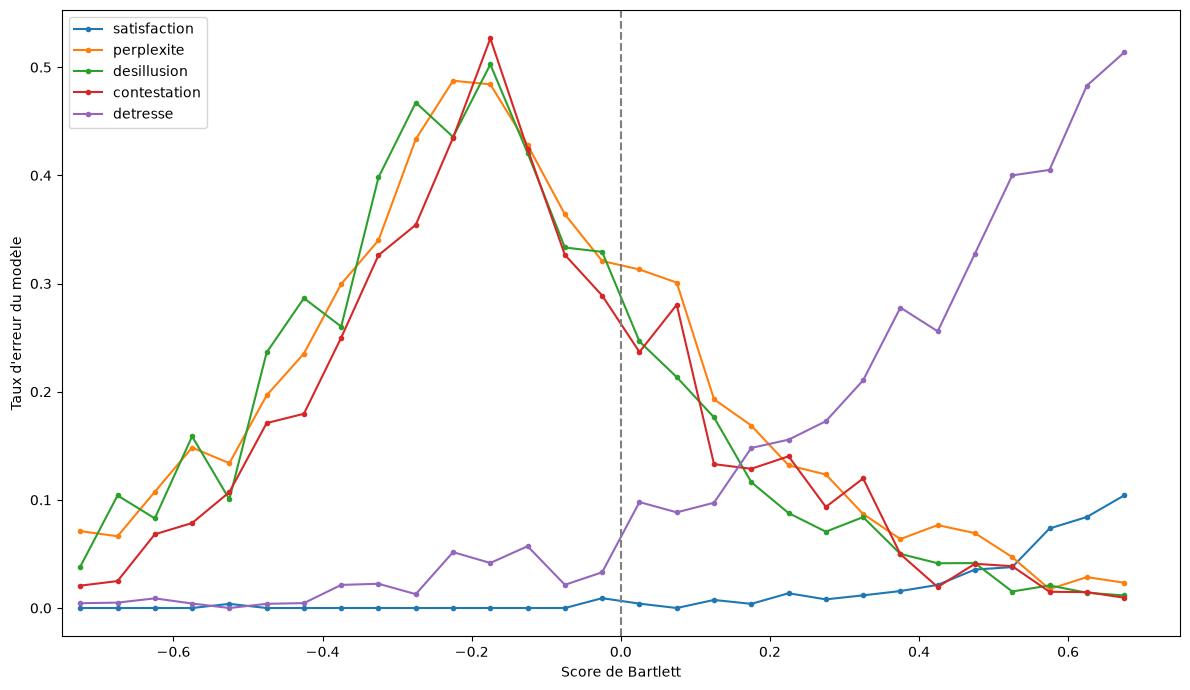

In [32]:
bins = np.arange(-0.75, 0.75, 0.05)  # tranches plus fines pour le zoom

df["tranche_zoom"] = pd.cut(df["score"], bins=bins)
taux = df.groupby(["emotion", "tranche_zoom"], observed=True)["erreur"].mean().reset_index()
taux["centre"] = taux["tranche_zoom"].apply(lambda x: x.mid).astype(float)

fig, ax = plt.subplots(figsize=(12, 7))
for e in EMOTIONS:
    t = taux[taux["emotion"] == e]
    ax.plot(t["centre"], t["erreur"], marker="o", markersize=3, label=e)

ax.axvline(0, color="gray", linestyle="--")
ax.set_xlim(-0.75, 0.75)
ax.set_xlabel("Score de Bartlett")
ax.set_ylabel("Taux d'erreur du modèle")
ax.legend()
plt.tight_layout()
plt.show()

# Temperature scalling pour améliorer la confiance

In [33]:
import torch.nn.functional as F
from scipy.optimize import minimize_scalar

# --- Logits bruts ---
out_valid = trainer.predict(encoded_dataset["valid"])
out_test = trainer.predict(encoded_dataset["test"])

logits_valid = torch.tensor(out_valid.predictions, dtype=torch.float32)
labels_valid = torch.tensor(out_valid.label_ids)
logits_test = torch.tensor(out_test.predictions, dtype=torch.float32)
labels_test = torch.tensor(out_test.label_ids)

def loss_avec_T(T, logits, labels):
    return F.cross_entropy(logits / T, labels).item()

# --- Recherche de la température sur la validation ---
res = minimize_scalar(loss_avec_T, bounds=(0.5, 20), method="bounded",
                      args=(logits_valid, labels_valid))
T = res.x
print(f"Température optimale : T = {T:.3f}\n")

# --- Effet sur la loss ---
for nom, logits, labels in [("validation", logits_valid, labels_valid),
                            ("test", logits_test, labels_test)]:
    avant = loss_avec_T(1.0, logits, labels)
    apres = loss_avec_T(T, logits, labels)
    print(f"{nom:10s} loss avant = {avant:.4f} | après = {apres:.4f}")

# --- Probabilités recalibrées ---
probs_test = F.softmax(logits_test / T, dim=-1).numpy()

[transformers] The following columns in the test set don't have a corresponding argument in `DebertaV2ForSequenceClassification.forward` and have been ignored: hypothesis, premise. If hypothesis, premise are not expected by `DebertaV2ForSequenceClassification.forward`,  you can safely ignore this message.
[transformers] 
***** Running Prediction *****
[transformers]   Num examples = 80480
[transformers]   Batch size = 16


[transformers] The following columns in the test set don't have a corresponding argument in `DebertaV2ForSequenceClassification.forward` and have been ignored: hypothesis, premise. If hypothesis, premise are not expected by `DebertaV2ForSequenceClassification.forward`,  you can safely ignore this message.
[transformers] 
***** Running Prediction *****
[transformers]   Num examples = 80485
[transformers]   Batch size = 16


Température optimale : T = 3.443

validation loss avant = 0.4839 | après = 0.2013
test       loss avant = 0.4825 | après = 0.2010


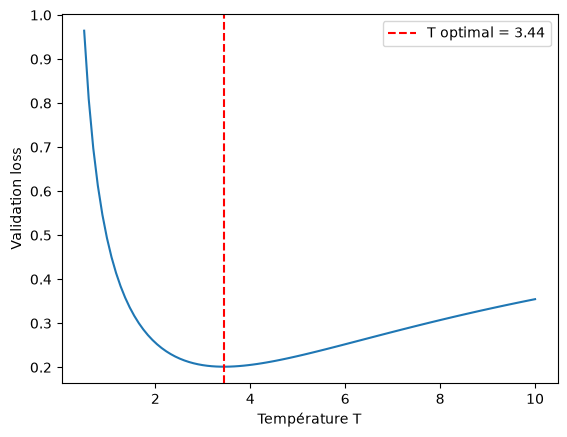

In [34]:
Ts = np.linspace(0.5, 10, 100)
losses = [loss_avec_T(t, logits_valid, labels_valid) for t in Ts]

plt.plot(Ts, losses)
plt.axvline(T, color="red", linestyle="--", label=f"T optimal = {T:.2f}")
plt.xlabel("Température T")
plt.ylabel("Validation loss")
plt.legend()
plt.show()

,modèle,loss,brier,ECE,accuracy,F1 macro
0,avant (T = 1),0.4839,0.0717,0.0713,0.927,0.9259
1,après (T = 3.578),0.2015,0.0575,0.0477,0.927,0.9259


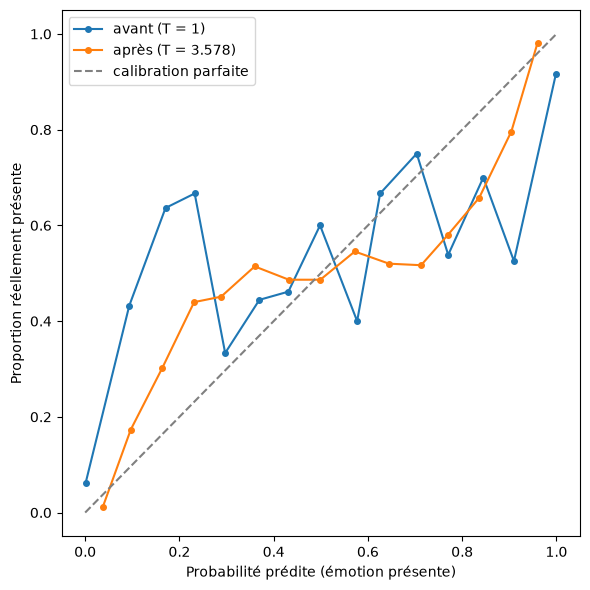

              precision    recall  f1-score   support

    entailed       0.91      0.92      0.92     35276
not entailed       0.94      0.93      0.93     45204

    accuracy                           0.93     80480
   macro avg       0.93      0.93      0.93     80480
weighted avg       0.93      0.93      0.93     80480



In [35]:
from sklearn.metrics import f1_score, accuracy_score, brier_score_loss, classification_report

PRESENTE = 0
T_OPT = 3.578

y = labels_valid.numpy()
y_bin = (y == PRESENTE).astype(int)  # 1 = émotion présente

def ece(p, y_bin, n_bins=15):
    """Expected Calibration Error : écart moyen entre confiance et fiabilité réelle."""
    bins = np.linspace(0, 1, n_bins + 1)
    idx = np.digitize(p, bins[1:-1])
    total = 0
    for b in range(n_bins):
        m = idx == b
        if m.any():
            total += m.mean() * abs(p[m].mean() - y_bin[m].mean())
    return total

resultats = []
probas = {}
for nom, T in [("avant (T = 1)", 1.0), (f"après (T = {T_OPT})", T_OPT)]:
    probs = F.softmax(logits_valid / T, dim=-1).numpy()
    p = probs[:, PRESENTE]
    pred = probs.argmax(axis=1)
    probas[nom] = p
    resultats.append({
        "modèle": nom,
        "loss": round(F.cross_entropy(logits_valid / T, labels_valid).item(), 4),
        "brier": round(brier_score_loss(y_bin, p), 4),
        "ECE": round(ece(p, y_bin), 4),
        "accuracy": round(accuracy_score(y, pred), 4),
        "F1 macro": round(f1_score(y, pred, average="macro"), 4),
    })

display(pd.DataFrame(resultats))

# --- Diagramme de fiabilité ---
fig, ax = plt.subplots(figsize=(6, 6))
bins = np.linspace(0, 1, 16)
for nom, p in probas.items():
    idx = np.digitize(p, bins[1:-1])
    conf = [p[idx == b].mean() for b in range(15) if (idx == b).any()]
    reel = [y_bin[idx == b].mean() for b in range(15) if (idx == b).any()]
    ax.plot(conf, reel, marker="o", markersize=4, label=nom)
ax.plot([0, 1], [0, 1], color="gray", linestyle="--", label="calibration parfaite")
ax.set_xlabel("Probabilité prédite (émotion présente)")
ax.set_ylabel("Proportion réellement présente")
ax.legend()
plt.tight_layout()
plt.show()

print(classification_report(y, F.softmax(logits_valid / T_OPT, dim=-1).argmax(dim=1).numpy(),
                            target_names=label_list))

# T par émotion

Hypothèses non reconnues : 0 



,émotion,n,T propre,loss T=1,loss T global,loss T propre,ECE T global,ECE T propre
0,satisfaction,16096,2.873,0.2359,0.1155,0.1083,0.0415,0.0185
1,perplexite,16096,3.651,0.5842,0.2352,0.2351,0.0542,0.0550
2,desillusion,16096,3.468,0.5034,0.2092,0.2091,0.0489,0.0466
3,contestation,16096,3.399,0.4653,0.1959,0.1954,0.0435,0.0402
4,detresse,16096,3.747,0.6305,0.2520,0.2516,0.0510,0.0549


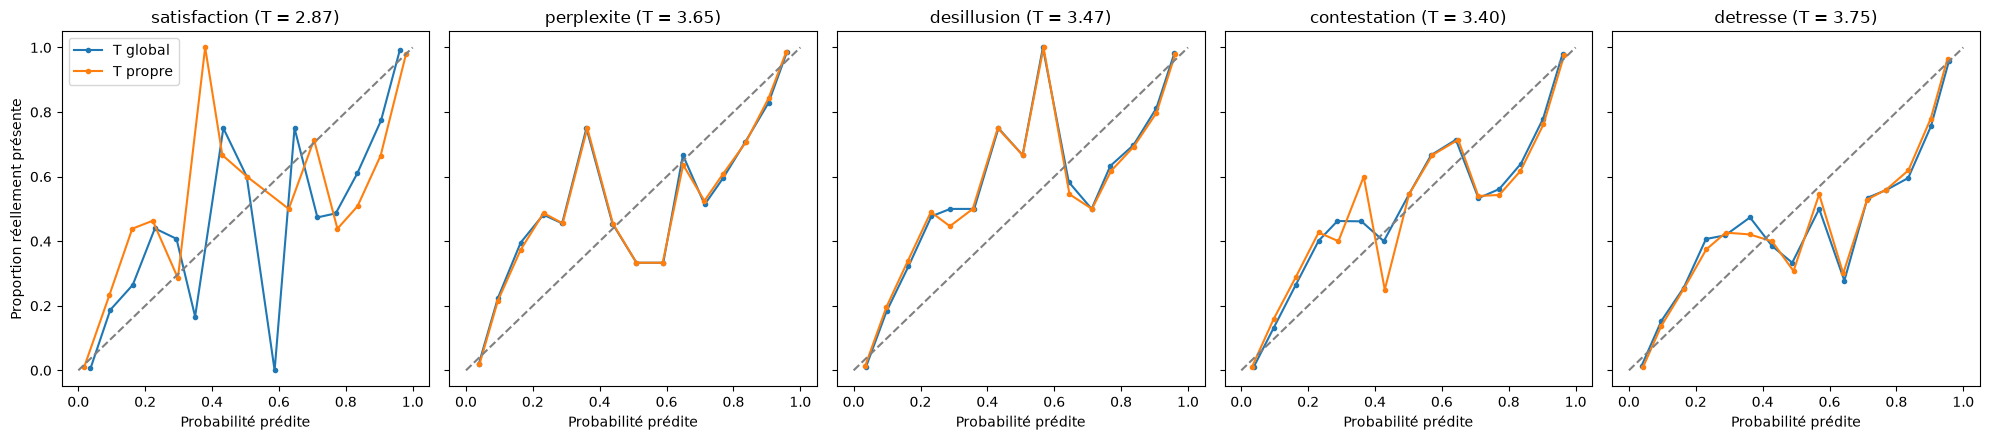

In [36]:
import unicodedata
from scipy.optimize import minimize_scalar

PRESENTE = 0
T_GLOBAL = 3.578
EMOTIONS = ["satisfaction", "perplexite", "desillusion", "contestation", "detresse"]

def sans_accents(s):
    return unicodedata.normalize("NFKD", s).encode("ascii", "ignore").decode().lower()

def trouver_emotion(h):
    h = sans_accents(h)
    return next((e for e in EMOTIONS if e in h), "inconnue")

# Émotion de chaque exemple (même ordre que les logits)
emotions_valid = np.array([trouver_emotion(h) for h in encoded_dataset["valid"]["hypothesis"]])
print("Hypothèses non reconnues :", (emotions_valid == "inconnue").sum(), "\n")

def ece(p, y_bin, n_bins=15):
    bins = np.linspace(0, 1, n_bins + 1)
    idx = np.digitize(p, bins[1:-1])
    return sum((idx == b).mean() * abs(p[idx == b].mean() - y_bin[idx == b].mean())
               for b in range(n_bins) if (idx == b).any())

lignes = []
T_par_emotion = {}

for e in EMOTIONS:
    m = torch.tensor(emotions_valid == e)
    lg, lb = logits_valid[m], labels_valid[m]
    y_bin = (lb.numpy() == PRESENTE).astype(int)

    res = minimize_scalar(loss_avec_T, bounds=(0.5, 20), method="bounded", args=(lg, lb))
    T_e = res.x
    T_par_emotion[e] = T_e

    p_global = F.softmax(lg / T_GLOBAL, dim=-1)[:, PRESENTE].numpy()
    p_propre = F.softmax(lg / T_e, dim=-1)[:, PRESENTE].numpy()

    lignes.append({
        "émotion": e,
        "n": int(m.sum()),
        "T propre": round(T_e, 3),
        "loss T=1": round(loss_avec_T(1.0, lg, lb), 4),
        "loss T global": round(loss_avec_T(T_GLOBAL, lg, lb), 4),
        "loss T propre": round(loss_avec_T(T_e, lg, lb), 4),
        "ECE T global": round(ece(p_global, y_bin), 4),
        "ECE T propre": round(ece(p_propre, y_bin), 4),
    })

display(pd.DataFrame(lignes))

# --- Diagrammes de fiabilité par émotion ---
fig, axes = plt.subplots(1, 5, figsize=(20, 4.5), sharey=True)
bins = np.linspace(0, 1, 16)

for ax, e in zip(axes, EMOTIONS):
    m = torch.tensor(emotions_valid == e)
    lg, lb = logits_valid[m], labels_valid[m]
    y_bin = (lb.numpy() == PRESENTE).astype(int)

    for nom, T in [("T global", T_GLOBAL), ("T propre", T_par_emotion[e])]:
        p = F.softmax(lg / T, dim=-1)[:, PRESENTE].numpy()
        idx = np.digitize(p, bins[1:-1])
        conf = [p[idx == b].mean() for b in range(15) if (idx == b).any()]
        reel = [y_bin[idx == b].mean() for b in range(15) if (idx == b).any()]
        ax.plot(conf, reel, marker="o", markersize=3, label=nom)

    ax.plot([0, 1], [0, 1], color="gray", linestyle="--")
    ax.set_title(f"{e} (T = {T_par_emotion[e]:.2f})")
    ax.set_xlabel("Probabilité prédite")

axes[0].set_ylabel("Proportion réellement présente")
axes[0].legend()
plt.tight_layout()
plt.show()

# Recap

In [60]:
from sklearn.metrics import f1_score

PRESENTE = 0
T_GLOBAL = 3.578

# --- Training loss : moyenne sur la dernière epoch (plus stable que la dernière valeur) ---
log_history = trainer.state.log_history
train_logs = [l for l in log_history if "loss" in l]
derniere_epoch = max(l["epoch"] for l in train_logs) - 1
train_loss = np.mean([l["loss"] for l in train_logs if l["epoch"] > derniere_epoch])

def resume(nom, logits, labels, T):
    pred = (logits / T).argmax(dim=1).numpy()
    y = labels.numpy()
    vrai_p, pred_p = y == PRESENTE, pred == PRESENTE
    fp, fn = (pred_p & ~vrai_p).sum(), (~pred_p & vrai_p).sum()
    return {
        "jeu": nom,
        "T": T,
        "training loss": round(train_loss, 4),
        "loss": round(F.cross_entropy(logits / T, labels).item(), 4),
        "F1 micro": round(f1_score(y, pred, average="micro"), 4),
        "F1 macro": round(f1_score(y, pred, average="macro"), 4),
        "nb FP": int(fp),
        "nb FN": int(fn),
        "taux FP": round(fp / (~vrai_p).sum(), 4),   # parmi les vrais « absents »
        "taux FN": round(fn / vrai_p.sum(), 4),      # parmi les vrais « présents »
    }

recap = pd.DataFrame([
    resume("validation", logits_valid, labels_valid, 1.0),
    resume("validation", logits_valid, labels_valid, T_GLOBAL),
    resume("test", logits_test, labels_test, 1.0),
    resume("test", logits_test, labels_test, T_GLOBAL),
])

display(recap)
recap.to_csv("recapitulatif_modele.csv", index=False)

,jeu,T,training loss,loss,F1 micro,F1 macro,nb FP,nb FN,taux FP,taux FN
0,validation,1.000,0.0716,0.5606,0.9128,0.9128,3768,3247,0.0933,0.0810
1,validation,3.578,0.0716,0.2304,0.9128,0.9128,3768,3247,0.0933,0.0810
2,test,1.000,0.0716,0.5706,0.9104,0.9104,3893,3320,0.0962,0.0829
3,test,3.578,0.0716,0.2336,0.9104,0.9104,3893,3320,0.0962,0.0829


In [61]:
PRESENTE = 0
T_GLOBAL = 3.578
SEUIL_NEUTRE = None  # ex. 0.6 pour taguer « neutre » si la probabilité max est trop basse

# --- Probabilité de présence pour chaque paire texte/émotion ---
p_presente = F.softmax(logits_valid / T_GLOBAL, dim=-1)[:, PRESENTE].numpy()

paires = pd.DataFrame({
    "premise": encoded_dataset["valid"]["premise"],
    "emotion": emotions_valid,
    "p_presente": p_presente,
})

# --- Une ligne par expérience, une colonne par émotion ---
experiences = paires.pivot_table(index="premise", columns="emotion", values="p_presente")[EMOTIONS]

experiences["emotion_max"] = experiences[EMOTIONS].idxmax(axis=1)
experiences["p_max"] = experiences[EMOTIONS].max(axis=1)

if SEUIL_NEUTRE is not None:
    experiences.loc[experiences["p_max"] < SEUIL_NEUTRE, "emotion_max"] = "neutre"

# --- Répartition ---
repartition = pd.DataFrame({
    "nb expériences": experiences["emotion_max"].value_counts(),
    "%": (100 * experiences["emotion_max"].value_counts(normalize=True)).round(1),
})

print(len(experiences), "expériences")
display(repartition)
display(experiences.head(10))

16096 expériences


,nb expériences,%
emotion_max,,
satisfaction,4181,26.0
perplexite,3578,22.2
contestation,3498,21.7
desillusion,3070,19.1
detresse,1769,11.0


emotion,satisfaction,perplexite,desillusion,contestation,detresse,emotion_max,p_max
premise,,,,,,,
"""Action non autorisée"" lors de la connexion\n\nBonjour,\n\nCela fait plusieurs tentatives pour me connecter à mon espace ANTS et le même message qui s'affiche : ""Action non autorisée"". Pourtant, l'identifiant et le mot de passe sont les bons, j'ai bien vérifié ! Impossible de se connecter via France Connect, une page d'erreur s'ouvre à chaque fois que j'essaie.\n\nJe suis bien embêté pour réaliser mes démarches en ligne ...",0.031629,0.932767,0.270482,0.919365,0.177871,perplexite,0.932767
"""Action non autorisée"" lors de la connexion sur ANTS\n\nBonjour,\n\nJ'ai fait une demande de permis de conduire. \n\nMaintenant, lorsque je saisis mon identifiant et mon mot de passe sur le site ANTS, un message d'erreur encadré en rouge s'affiche : ""ACTION NON AUTORISÉE"". \n\nJ'ai même changé mon mot de passe après, mais je rencontre toujours le même problème : un message d'erreur encadré en rouge s'affiche : ""ACTION NON AUTORISÉE"".",0.811154,0.965169,0.913140,0.042870,0.921004,perplexite,0.965169
"""C'était mieux avant""\n\nJ'ai bientôt 65 ans, je me souviens que jusqu'à une date récente, quand j'avais une question sur les impôts, j'allais dans les bureaux des contributions, on attendait un peu, on était reçu et on recevait la solution immédiatement en face à face. Maintenant c'est devenu un petit parcours du combattant :\n- il faut poser les questions dans la messagerie, mais ce n'est pas évident quand ce n'est pas son métier de poser la bonne question, bien claire et quand on reçoit la réponse, après des jours, elles ne sont pas toujours claires et donc on doit poser de nouvelles questions, ce n'est pas assez intuitif.\n- et puis quand on n'y arrive toujours pas, on doit prendre un rdv par téléphone ou sur place et les rdv c'est pas toujours dans les jours qui suivent.\nBref, je dis qu'avec l'informatique, c'est bien quand on n'a pas de problème, c'est bien quand on comprend le langage de l'administration et sinon, c'est plus difficile qu'avant, je dis que l'administration s'est éloignée des citoyens, c'est dommage pour un pays si riche.",0.911167,0.952233,0.942496,0.871481,0.237791,perplexite,0.952233
"""Certaines informations que vous avez saisies sont incorrectes""\n\nJ’essaie de créer mon compte sur le site afin de renouveler mon titre de séjour ; le message d’erreur que je reçois est : « Certaines informations que vous avez saisies sont incorrectes, veuillez vérifier votre saisie. »",0.076612,0.965556,0.920109,0.031589,0.931881,perplexite,0.965556
"""Chômage indemnisé - Attestation régularisation de carrière"" par la Carsat\n\nAu chômage et âgé de 61 ans et 11 mois, France Travail me prévient qu’à défaut de présentation du justificatif « Chômage indemnisé – Attestation de régularisation de carrière » précisant la date à laquelle je pourrai bénéficier d’une retraite à taux plein, mon indemnisation cessera à mes 62 ans et 6 mois (mon âge légal pour prétendre à la retraite).\n\nJe contacte téléphoniquement la CARSAT et j’apprends que je suis rattaché à la CARSAT Normandie, alors que j’habite en Creuse depuis un an et demi. Ils ont bien enregistré mon changement d’adresse, mais continuent de gérer ma pension de réversion. Il me faudra effectuer trois appels avant qu’ils me disent que je dois demander ce document par courrier, en y joignant la demande écrite de France Travail. Résultat : un mois de perdu. J’ai désormais 62 ans.\n\nJe demande alors le courrier à France Travail, qui ne peut pas le fournir, mais m’envoie un mail de demande de cette attestation pour me sortir de l’impasse. J’imprime le mail et le joins à ma demande, envoyée en recommandé avec accusé de réception le 26/08/2024. Le lendemain, je reçois enfin le courrier papier de France Travail…\n\nTous les mois, j’appelle la CARSAT (je tombe toujours sur la Normandie) pour suivre l’avancement de ma demande. Elle est « en cours de traitement » jusqu’au 03/03/2025, date